# ModServe evaluation

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else '.'
sys.path.insert(0, os.path.join(ROOT, 'src'))
os.environ.setdefault('HF_HUB_OFFLINE', '1')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from lmm_serving.experiments import scoring
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
PM = os.path.join(ROOT, 'persisted_metrics')

## TTFT comparison (InternVL-26B, DecOnly), fixed 24 GPUs, no autoscaling

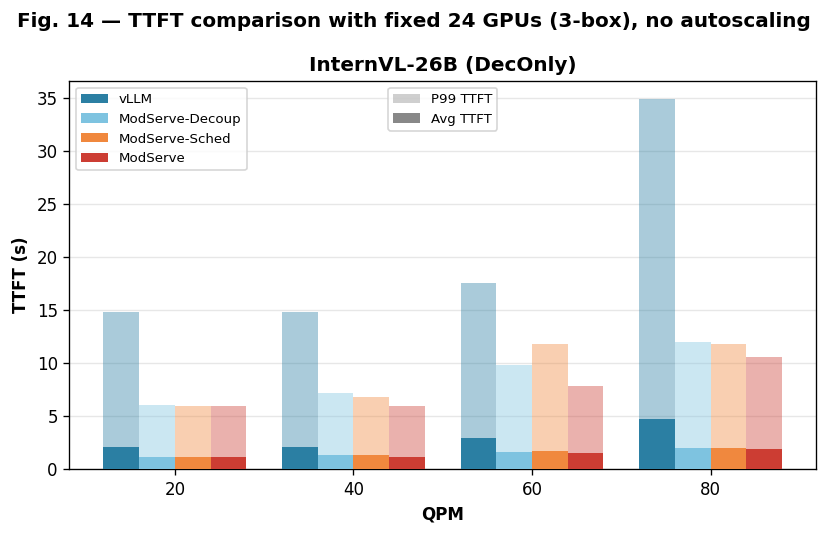

In [2]:
QPM = {'7.77': 20, '3.89': 40, '2.59': 60, '1.94': 80}
SYS = {'vLLM':            'monolith_3box_internvl_knee_scale{s}',
       'ModServe-Decoup': 'fig14_decoup_internvl_s{s}',
       'ModServe-Sched':  'fig14_sched_internvl_s{s}',
       'ModServe':        'modserve_3box_internvl_knee_scale{s}'}
ORDER = list(SYS)
# paper palette: vLLM teal, Decoup light-blue, Sched orange, ModServe red
COLOR = {'vLLM': '#2b7fa3', 'ModServe-Decoup': '#7ec3e0', 'ModServe-Sched': '#f0883e', 'ModServe': '#cc3d33'}

rows = []
for s, pat in SYS.items():
    for sc, qpm in QPM.items():
        d = os.path.join(PM, pat.format(s=sc))
        if os.path.exists(os.path.join(d, 'cluster_manager_metrics.csv')):
            z = scoring.summarize(scoring.load_run(d))
            rows.append(dict(system=s, qpm=qpm, p99=z['p99_ttft_all']/1000, avg=z['mean_ttft_all']/1000))
ttft = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4.5))
qpms = sorted(QPM.values()); x = np.arange(len(qpms)); w = 0.8 / len(ORDER)
for i, s in enumerate(ORDER):
    g = ttft[ttft.system == s].set_index('qpm').reindex(qpms)
    xs = x + (i - (len(ORDER)-1)/2) * w
    ax.bar(xs, g.p99, w, color=COLOR[s], alpha=0.4, zorder=2, label=s)   # P99 (translucent)
    ax.bar(xs, g.avg, w, color=COLOR[s], zorder=3)                       # Avg (solid)
ax.set_title('InternVL-26B (DecOnly)', fontweight='bold')
ax.set_xlabel('QPM', fontweight='bold'); ax.set_ylabel('TTFT (s)', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(qpms); ax.grid(True, axis='y', alpha=0.3)
leg1 = ax.legend(handles=[Patch(facecolor=COLOR[s], label=s) for s in ORDER], loc='upper left', fontsize=8)
ax.add_artist(leg1)
ax.legend(handles=[Patch(facecolor='#888', alpha=0.4, label='P99 TTFT'),
                   Patch(facecolor='#888', label='Avg TTFT')], loc='upper center', fontsize=8)
fig.suptitle('Fig. 14 — TTFT comparison with fixed 24 GPUs (3-box), no autoscaling', fontweight='bold')
fig.tight_layout(); plt.show()

## Autoscaling (Llama3.2-11B, CroAttn)

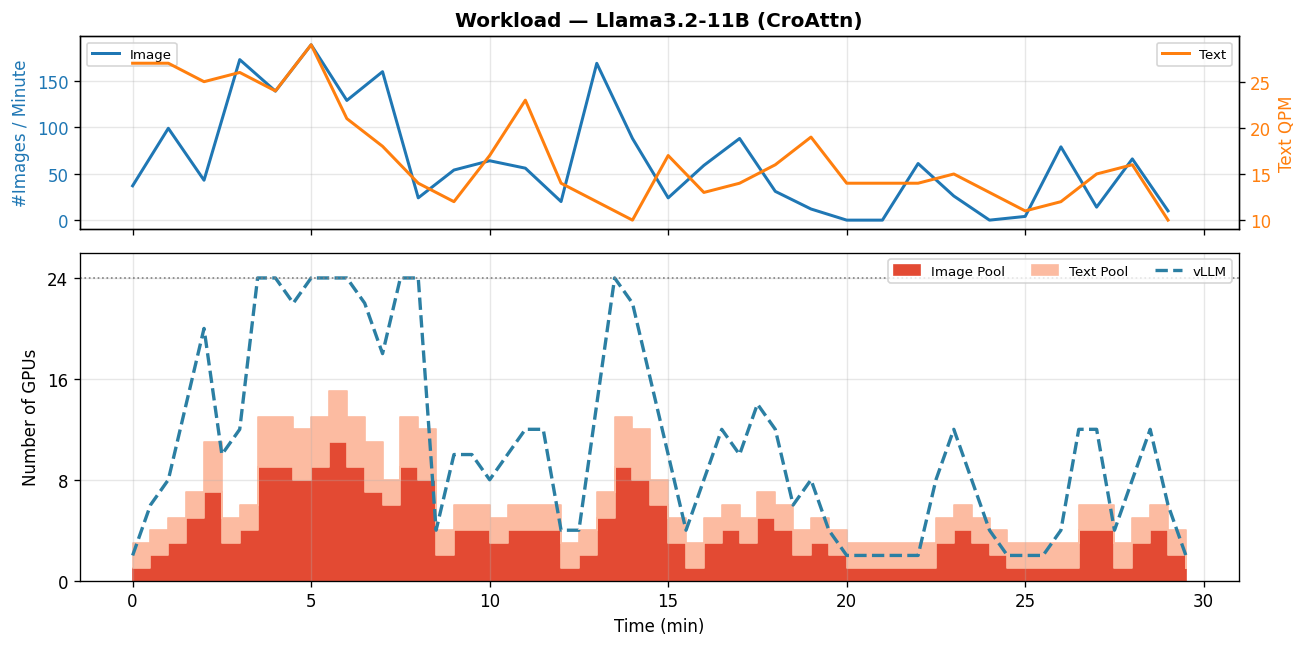

In [4]:
TP = 2   # Llama text/monolith nodes deploy at TP2

def _auto(name):
    d = pd.read_csv(os.path.join(PM, name, 'autoscale_metrics.csv'))
    d = d[pd.to_numeric(d.wall_time, errors='coerce').notna()].apply(pd.to_numeric, errors='coerce')
    d['t_min'] = (d.wall_time - d.wall_time.iloc[0]) / 60
    return d

mod, mono = _auto('modserve_autoscale_llama_3box'), _auto('monolith_autoscale_llama_3box')
tmax = min(mod.t_min.max(), mono.t_min.max())          # compare over the shared window
mod, mono = mod[mod.t_min <= tmax], mono[mono.t_min <= tmax]
cm = pd.read_csv(os.path.join(PM, 'modserve_autoscale_llama_3box', 'cluster_manager_metrics.csv'))
cm = cm[pd.to_datetime(cm.timestamp, errors='coerce').notna()].copy()
cm['min'] = ((pd.to_datetime(cm.timestamp) - pd.to_datetime(cm.timestamp).min()).dt.total_seconds() // 60).astype(int)
wl = cm[cm['min'] <= tmax].groupby('min').agg(images=('num_images', 'sum'),
         text_qpm=('num_images', lambda s: (s == 0).sum())).reset_index()

fig, (a0, a1) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True,
                             gridspec_kw={'height_ratios': [1, 1.7]})
a0.plot(wl['min'], wl.images, color='#1f77b4', lw=1.8, label='Image')
a0.set_ylabel('#Images / Minute', color='#1f77b4'); a0.tick_params(axis='y', labelcolor='#1f77b4')
a0.set_title('Workload — Llama3.2-11B (CroAttn)', fontweight='bold'); a0.grid(True, alpha=0.3)
a0b = a0.twinx(); a0b.plot(wl['min'], wl.text_qpm, color='#ff7f0e', lw=1.8, label='Text')
a0b.set_ylabel('Text QPM', color='#ff7f0e'); a0b.tick_params(axis='y', labelcolor='#ff7f0e')
a0.legend(loc='upper left', fontsize=8); a0b.legend(loc='upper right', fontsize=8)
img_gpu = mod.image_active                 # TP1 encoders, 1 GPU each
txt_gpu = mod.text_active * TP             # TP2 text nodes
a1.fill_between(mod.t_min, 0, img_gpu, step='post', color='#e34a33', label='Image Pool')
a1.fill_between(mod.t_min, img_gpu, img_gpu + txt_gpu, step='post', color='#fcbba1', label='Text Pool')
a1.plot(mono.t_min, mono.monolith_active * TP, color='#2b7fa3', lw=2, ls='--', label='vLLM')
a1.axhline(24, color='0.5', ls=':', lw=1)
a1.set(xlabel='Time (min)', ylabel='Number of GPUs', ylim=(0, 26), yticks=[0, 8, 16, 24])
a1.legend(loc='upper right', fontsize=8, ncol=3); a1.grid(True, alpha=0.3)
fig.tight_layout(); plt.show()